<a href="https://colab.research.google.com/github/walevez/ProcesamientoDelHabla/blob/main/CHAVEZ_WALTER_PH_TP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Procesamiento de Habla - TP2

Alumno: Chavez Walter Emanuel

### Contenido del PDF
Informa del Evento el Ninio, de como podria afectar la provincia de Corrientes.

In [ ]:
! pip install pymupdf
! pip install pdfplumber
! pip install spacy
! python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 35.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Librerias importadas para el desarrollo de la consigna.

In [ ]:
import requests
import pymupdf
import pdfplumber
import pandas as pd
import spacy
import unicodedata
import matplotlib.pyplot as plt
from collections import Counter

## 1. Adquisición y metadatos
Descarga: Utilizando las librerías requests o urllib, descarga un archivo PDF desde un enlace público (por ejemplo, un artículo científico de arXiv o un reporte institucional).

No puede usar el mismo pdf o enlace que otra persona ya haya presentado en el foro. El PDF elegido debe contener texto extraible, no deben ser páginas escaneadas tipo imagen.

Inspección: Muestra por pantalla los metadatos del archivo: título, autor, número de páginas y software de creación.

Sugerencia: Puedes utilizar librerías como PyMuPDF (fitz) o PyPDF2.

## Descarga del PDF y Visualizacion de los MetaDatos.

In [ ]:
#Importacion de archivo PDF desde la web.
url = 'https://www.argentina.gob.ar/sites/default/files/2024/05/el_fenomeno_el_nino_2026_rrnn_eea_ctes_v2.pdf'
nombre_pdf = 'el_nino_en_corrientes.PDF'

#Funcion que descargar el pd y lo guarda en local(google drive)
def descargar_pdf(url, nombre_pdf):
  try:
    response = requests.get(url, stream=True)

    with open(nombre_pdf, 'wb') as archivo:
      for chunk in response.iter_content(chunk_size=8192):
        archivo.write(chunk)

  except requests.exceptions.RequestException as e:
    print(f'Error al descargar PDF: {e}')

  return f'/content/{nombre_pdf}'

ruta_pdf = descargar_pdf(url, nombre_pdf)

#Informacion del archivo descargado
doc = pymupdf.Document(ruta_pdf)
print(f'El titulo del PDF es: {doc.metadata.get('title')}')
print(f'El autor del PDF es: {doc.metadata.get('author')}')
print(f'El numero de paginas del PDF son: {doc.page_count}')
print(f'Software Creador: {doc.metadata.get('creator')}')

El titulo del PDF es: 
El autor del PDF es: INTA
El numero de paginas del PDF son: 11
Software Creador: Microsoft® Word para Microsoft 365


### 2. Análisis estructural del texto
Extracción cruda: Extrae el texto del PDF.. Identifica la función de la librería elegida que te ayuda en esta tarea y te permite ver el texto extraído lo más crudo posible.

Análisis de separadores: Observa y describe cómo están separados los párrafos, las secciones y los capítulos.

Identificación de caracteres: ¿Qué caracteres especiales funcionan como separadores de línea o de bloque en este archivo específico? (Ej: \n, \r, \t o secuencias de espacios).

## Texto completo crudo

El texto extraido se muestras crudo, este esta concatenado pagina por pagina, use el metodo repr al imprimir para que muestre los separadores de lineas o bloques correspondiente.

In [ ]:
texto_completo = ''

for pagina in doc:
  texto_pagina = pagina.get_text()
  if texto_pagina:
    texto_completo += texto_pagina

print(repr(texto_completo))

'  \n \n¿Qué podría pasar en \nCorrientes con un \nevento El Niño \nextremo? \nAnálisis de la superficie potencialmente afectable por \nexceso hídrico a partir del antecedente del año 1998 \nDitmar B. Kurtz, Griselda I. Saucedo, Carolina Fernández López, Alba R. \nPerucca \nGrupo Recursos Naturales EEA Corrientes - INTA \nINFORME  \nEEA Corrientes - INTA \n  \nAutores \nDitmar B. Kurtz,  \nGriselda I. Saucedo,  \nCarolina Fernández López,  \nAlba R. Perucca \n \n \n \n \n \n \n \nINFORME \n¿Qué podría pasar en Corrientes con un evento El Niño \nextremo? \nAnálisis de la superficie potencialmente afectable por exceso hídrico a \npartir del antecedente del año 1998 \nEdición: \nEstación Experimental Agropecuaria Corrientes INTA. CENTRO REGIONAL CORRIENTES \nJunio 2026 \n  \n¿Qué puede pasar en Corrientes con un evento El Niño \nextremo? \n \nAnálisis de la superficie potencialmente afectable por exceso hídrico a \npartir del antecedente del año 1998 \n \nDitmar B. Kurtz, Griselda I. Sauc

### 3. Extracción de datos tabulares
Busca una página en el PDF que contenga una tabla de datos.

Extrae dicha tabla y conviértela en un DataFrame de Pandas.

Realiza una limpieza básica de la tabla (nombrar columnas, eliminar filas vacías).

Sugerencia: Se recomienda el uso de pdfplumber o tabula-py.

### Extracción de datos tabulares

In [ ]:
pagina_objetivo = 11

with pdfplumber.open(ruta_pdf) as pdf:
    pagina = pdf.pages[pagina_objetivo - 1]
    tablas = pagina.extract_tables()

    if not tablas:
        print("No se detectaron tablas")
    else:
        #Aca tomo la primera tabla que aparece en la pagina(en el caso que alla varias)
        df_raw = pd.DataFrame(tablas[0])

        #Trabajar con pdfplumber produce error de encabezados al momento de crear la tabla
        #Aqui ignoro las primera filas hasta los datos relevantes
        data_start = 12

        df_data = df_raw.iloc[data_start:].reset_index(drop=True)

        #Nombro las columnas correctamente (segun la tabla original)
        columnas = [
            "Departamento",
            "Superficie del departamento (ha)",
            "Superficie cubierta con agua en abril/mayo de 1998 (ha)",
            "%",
            "Superficie cubierta con agua en abril de 2026 (ha)",
            "%",
            "Diferencia 1998-2026 (ha)"
        ]

        df_data.columns = columnas

        #Limpio las filas vacias
        df_data = df_data.dropna(how="all").reset_index(drop=True)

        display(df_data)

,Departamento,Superficie del departamento (ha),Superficie cubierta con agua en abril/mayo de 1998 (ha),%,Superficie cubierta con agua en abril de 2026 (ha),%,Diferencia 1998-2026 (ha)
0,Bella Vista,179.892,132.383,74,34.575,19,97.808
1,Berón de Astrada,87.044,75.114,86,23.344,27,51.770
2,Capital,56.225,36.804,65,9.438,17,27.367
3,Concepción,528.297,403.410,76,237.258,45,166.152
4,Curuzú Cuatiá,832.111,195.959,24,30.205,4,165.754
5,Empedrado,197.176,159.363,81,41.456,21,117.907
6,Esquina,394.512,321.161,81,76.546,19,244.615
7,General Alvear,194.120,112.337,58,9.074,5,103.263
8,General Paz,260.693,229.569,88,102.190,39,127.379
9,Goya,483.423,355.044,73,81.958,17,273.086


### 4. Análisis de frecuencias (NLP básico)
Elige una página que contenga únicamente texto narrativo, usa la biblioteca nltk o spacy  y realiza lo siguiente:

Tokenización: Extrae el texto y conviértelo a minúsculas.

Limpieza: Elimina las stop words (palabras funcionales sin peso semántico como "el", "de", "y") y signos de puntuación.

Visualización: Genera un gráfico de barras que muestre las 15 palabras más frecuentes en esa página. ¿ Te surgieron en esta visualización tokens que también considerarías stop words? Comenta y justifica.

### Tokenizacion y limpieza

In [ ]:
ntl = spacy.load('es_core_news_sm')
pagina = doc.get_page_text(2)

#prompt: necesito quitar las letras con acentos, ense;ame una funcion que pueda llamar en mi list comprehension
def eliminar_acentos(texto):
    # Descompone los caracteres (ej. 'é' se convierte en 'e' + '´')
    texto_normalizado = unicodedata.normalize('NFD', texto)
    # Filtra y une solo los caracteres que no sean marcas de acentuación (Mn)
    return "".join(c for c in texto_normalizado if unicodedata.category(c) != 'Mn')

documento = ntl(pagina)
tokens = [
    eliminar_acentos(token.text.lower())
    for token in documento
    if not token.is_stop and not token.is_punct and token.is_alpha
]

### Visualizacion
En la visualizacion no considero que las palabras que tienen mayor frecuencia en la pagina que seleccione, sean stop words, las palabras que muestra el grafico si se presta atencion dan sentido al PDF y de que se trata su contenido.

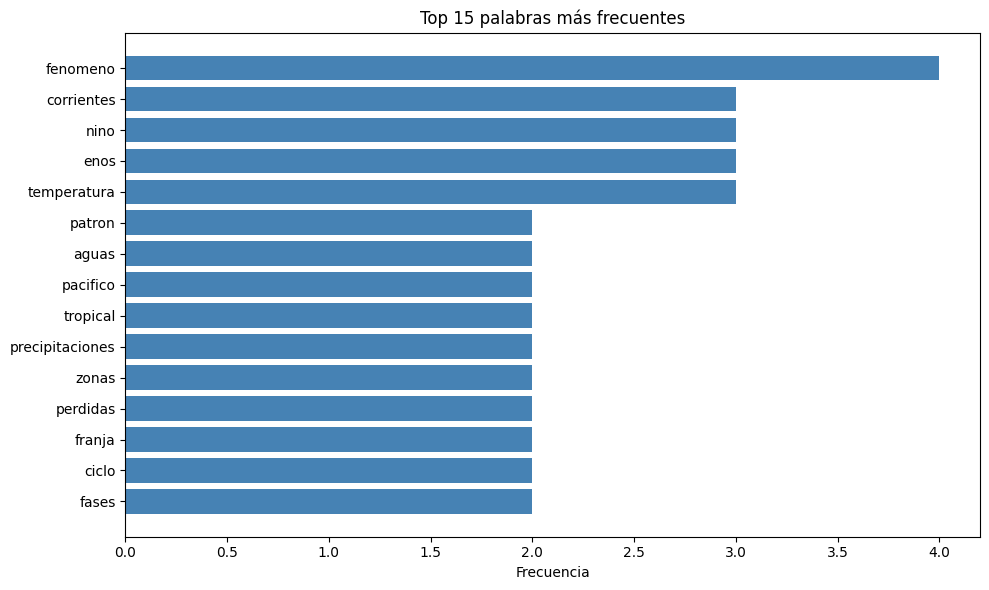

In [ ]:
#prompt: Ahora necesito contar las palabras extraidas para hacer un grafico de barra de las 15 primeras
# Contar las palabras
conteo = Counter(tokens)

# Top 15
top_15 = conteo.most_common(15)

# Pasar a DataFrame para graficar más fácil
df_top = pd.DataFrame(top_15, columns=["palabra", "frecuencia"])

# Gráfico de barras
plt.figure(figsize=(10, 6))
plt.barh(df_top["palabra"][::-1], df_top["frecuencia"][::-1], color="steelblue")  # [::-1] para que la más frecuente quede arriba
plt.xlabel("Frecuencia")
plt.title("Top 15 palabras más frecuentes")
plt.tight_layout()
plt.show()